<a href="https://colab.research.google.com/github/Ayushprajapati2006/BIS-LAB/blob/main/Parallel_cellular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simulated 1000 parallel steps on a 300x300 grid in 318.09 ms


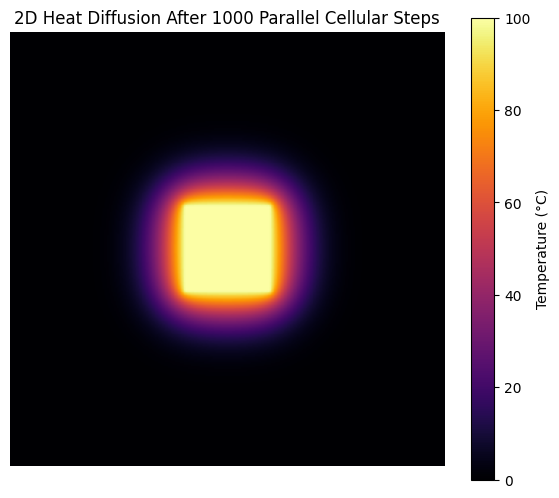

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# Parallel Cellular Rule: 2D Heat Diffusion (Finite Difference Method)
@njit(parallel=True)
def step_heat_diffusion(grid):
    rows, cols = grid.shape
    new_grid = grid.copy()

    # Update all interior cells simultaneously across CPU cores
    for r in prange(1, rows - 1):
        for c in range(1, cols - 1):
            # Each cell's new temperature is the average of its 4 von Neumann neighbors
            new_grid[r, c] = 0.25 * (
                grid[r - 1, c] + # Top
                grid[r + 1, c] + # Bottom
                grid[r, c - 1] + # Left
                grid[r, c + 1]   # Right
            )

    return new_grid

# --- Simulation Setup ---
GRID_SIZE = 300
STEPS = 1000

# 1. Initialize a 300x300 grid at 0 degrees
plate = np.zeros((GRID_SIZE, GRID_SIZE), dtype=np.float64)

# 2. Warm-up call to compile the Numba function
_ = step_heat_diffusion(plate)

# 3. Run the parallel cellular simulation
start_time = time.time()

for _ in range(STEPS):
    # Maintain a constant 100-degree heat source in the center square
    plate[120:180, 120:180] = 100.0
    # Advance the entire grid by one parallel time step
    plate = step_heat_diffusion(plate)

end_time = time.time()
print(f"Simulated {STEPS} parallel steps on a {GRID_SIZE}x{GRID_SIZE} grid in {(end_time - start_time)*1000:.2f} ms")

# 4. Visualize the final temperature distribution in Colab
plt.figure(figsize=(7, 6))
plt.imshow(plate, cmap='inferno', origin='lower')
plt.colorbar(label='Temperature (°C)')
plt.title(f'2D Heat Diffusion After {STEPS} Parallel Cellular Steps')
plt.axis('off')
plt.show()
